# CampusPulse: what the three pulses say together
① Academic (Portugal), ③ Wellbeing (US high schools) and ⑤ Energy (IIIT Delhi) describe different people in
different places, so we never join their rows. We compare their conclusions and how fragile each one is.

In [1]:
import sys, os
from pathlib import Path
for cand in [Path.cwd(), Path.cwd().parent]:
    if (cand / 'campuspulse').exists():
        sys.path.insert(0, str(cand)); break
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from campuspulse.academic import pipeline as P_acad
from campuspulse.wellbeing import pipeline as P_well
from campuspulse.energy import pipeline as P_ener
from campuspulse.common.decisions import robustness_matrix, survival_summary, defaults
from campuspulse.common.plots import theme
theme()

## Link: sleep (survey) and the campus at night (meters)
Students report more sadness when they sleep less. The hostel meters show how much the campus is awake at night in
term versus vacation. A comparison of patterns, not a measurement of anyone's sleep.

W1 sadness gap, sleep-deprived vs rested: +18.1 pp
EN2 hostel night power, term vs vacation: +12,169 W (same month, EN3: +10,366 W)


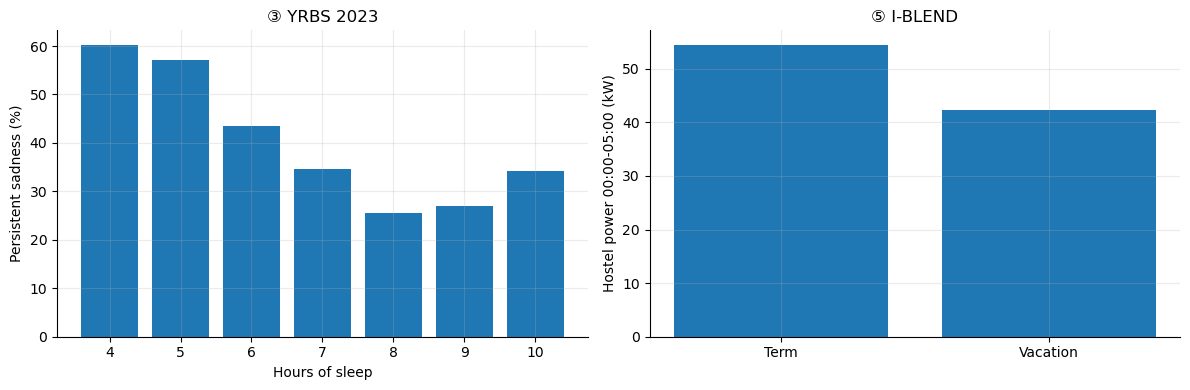

In [2]:
res_w = P_well.run_pipeline(defaults(P_well.DECISIONS))
res_en = P_ener.run_pipeline(defaults(P_ener.DECISIONS))
yr, _ = P_well.clean(defaults(P_well.DECISIONS))
sleep = yr.groupby("sleep_hours").apply(lambda g: np.average(g["sadness"], weights=g["w"]))
en = P_ener.clean(defaults(P_ener.DECISIONS))
night = en[en["is_late_night"] == 1].groupby("is_vacation")["total_hostel_power"].mean() / 1000
print(f"W1 sadness gap, sleep-deprived vs rested: {res_w['W1']*100:+.1f} pp")
print(f"EN2 hostel night power, term vs vacation: {res_en['EN2']:+,.0f} W (same month, EN3: {res_en['EN3']:+,.0f} W)")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(sleep.index.astype(int).astype(str), sleep.values * 100)
axes[0].set_xlabel("Hours of sleep"); axes[0].set_ylabel("Persistent sadness (%)"); axes[0].set_title("③ YRBS 2023")
axes[1].bar(["Term", "Vacation"], [night.get(0, np.nan), night.get(1, np.nan)])
axes[1].set_ylabel("Hostel power 00:00-05:00 (kW)"); axes[1].set_title("⑤ I-BLEND")
plt.tight_layout(); plt.show()

## How fragile is each pulse?

In [3]:
rows = []
for name, mod in [("Academic", P_acad), ("Wellbeing", P_well), ("Energy", P_ener)]:
    vals, _ = robustness_matrix(mod.run_pipeline, mod.DECISIONS, mod.FINDINGS)
    rows.append({"pulse": name, **survival_summary(vals)})
pd.DataFrame(rows)